# Notebook 2 — ANN Projects: MNIST + California Housing

**Course:** From Introduction to Advanced Deep Learning · **Topic 1: ANN** · 4 hours
**Projects:** P1 (MNIST image classification) and P2 (California Housing tabular regression)

> **What this notebook does.** Notebook 1 took you from a single linear neuron up to a dense 3-layer
> MLP. This notebook takes that MLP and applies it end-to-end on **two real datasets** that close
> Topic 1 of the course roadmap:
>
> - **Project P1 — MNIST.** 70,000 grayscale 28×28 images of handwritten digits, 10 classes.
>   Build an MLP that flattens each image to a 784-vector and classifies it. The deliverable is a
>   baseline accuracy plus a *diagnosis* of the loss curve (underfit / overfit / healthy).
> - **Project P2 — California Housing.** 20,640 rows × 8 numeric features, target = median house
>   value. Same MLP architecture, but the **output head and loss change**: a single linear unit and
>   MSE loss instead of a 10-way softmax and cross-entropy. The deliverable is MSE, MAE, and R² on a
>   held-out test set, compared to a sklearn linear-regression baseline.
>
> Together the two projects show that *the architecture is the same; what changes is the output head,
> the loss, and the metrics.* Mastering that distinction is the real point of Topic 1.

### The MLP architecture you will reuse
![A simple feed-forward MLP](https://upload.wikimedia.org/wikipedia/commons/thumb/e/e4/Artificial_neural_network.svg/640px-Artificial_neural_network.svg.png)

*Image: a feed-forward neural network with one hidden layer — the same architecture we will use,
just wider. By Glosser.ca, Wikipedia CC BY-SA 3.0.*

The picture above is the network we built in Notebook 1 §7: input → Linear → ReLU → Linear → ReLU →
Linear → output. The only differences between P1 and P2 are at the very top (output dimension and
loss function). Everything else — the forward pass, the backward pass, the optimiser step, the
training loop — is identical. That is the whole point of building a flexible MLP class.

In [1]:
# One-time setup: imports, seeds, device, plotting style.
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split

import torchvision
import torchvision.transforms as T

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix
import time

# Reproducibility — see Notebook 1 §12
def set_seed(seed=42):
    import random, os
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"torch: {torch.__version__},  torchvision: {torchvision.__version__}")

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

Device: cpu
torch: 2.14.1+cpu,  torchvision: 0.29.1+cpu


## Project P1 — MNIST Digit Classification

### Problem statement (from the course roadmap)
> *Classify handwritten digits from raw 28×28 pixels with an MLP; establish the baseline accuracy
> and diagnose the loss curve (underfit / overfit / dying ReLU).*

This is **P1 of Topic 1** — the first end-to-end deep-learning project in the course. By the end of
this section you will have trained a 3-layer MLP that gets ~97% test accuracy on MNIST, plotted its
loss curves, and built a confusion matrix that shows which digits the model confuses with each other.

### Dataset description
MNIST is the *"Hello World"* of deep learning:

| Property | Value |
|----------|-------|
| Total images | 70,000 (60k train + 10k test) |
| Image size | 28 × 28 grayscale pixels |
| Pixel range | 0 (black) to 255 (white) |
| Number of classes | 10 (digits 0–9) |
| Class balance | roughly uniform (~6,800 per class) |
| Source | torchvision (originally Yann LeCun et al.) |

We download it via `torchvision.datasets.MNIST`, which automatically normalises pixels to [0,1] and
splits into train/test. We further carve 5,000 images out of the 60k train set as a **validation
set** so we can detect overfitting during training.

### Why an MLP works on MNIST (and where it fails)
A 28×28 image flattens to a 784-dimensional vector. The MLP treats every pixel as an independent
feature and learns a dense weight matrix of shape `[784, hidden_dim]`. This works surprisingly well
because handwritten digits are mostly strokes in roughly the same screen position — the MLP can learn
per-pixel importance. It fails on tasks where the **spatial structure** matters (e.g. translating a
digit by 5 pixels destroys the prediction) — that is exactly what Convolutional Neural Networks
(Topic 2) fix. The MLP is your baseline; CNNs beat it.

### Code: load MNIST and inspect the data

In [2]:
# Load MNIST via torchvision. Pixels are normalised to [0,1] via ToTensor().
transform = T.Compose([T.ToTensor()])

train_full = torchvision.datasets.MNIST(root='/tmp/mnist', train=True,  download=True, transform=transform)
test_set   = torchvision.datasets.MNIST(root='/tmp/mnist', train=False, download=True, transform=transform)

# Carve a 5k validation set out of the 60k training set
set_seed(42)
train_set, val_set = random_split(train_full, [55000, 5000])

print(f"Train: {len(train_set)} images")
print(f"Val:   {len(val_set)} images")
print(f"Test:  {len(test_set)} images")

# Inspect one batch
images, labels = next(iter(DataLoader(train_set, batch_size=9, shuffle=True)))
print(f"\nBatch image tensor shape: {images.shape}  (batch, channels, H, W)")
print(f"Batch labels: {labels.tolist()}")
print(f"Pixel range: [{images.min():.3f}, {images.max():.3f}]")

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:56, 174kB/s]

  1%|          | 98.3k/9.91M [00:00<00:37, 263kB/s]

  2%|▏         | 164k/9.91M [00:00<00:33, 290kB/s] 

  4%|▎         | 360k/9.91M [00:00<00:17, 558kB/s]

...

 89%|████████▉ | 1.47M/1.65M [00:01<00:00, 1.48MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.07MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 2.59MB/s]

Train: 55000 images
Val:   5000 images
Test:  10000 images

Batch image tensor shape: torch.Size([9, 1, 28, 28])  (batch, channels, H, W)
Batch labels: [0, 1, 1, 0, 5, 6, 1, 2, 4]
Pixel range: [0.000, 1.000]


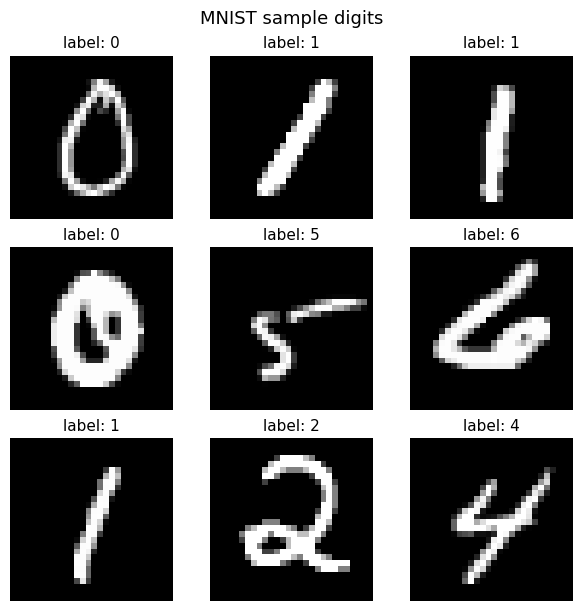

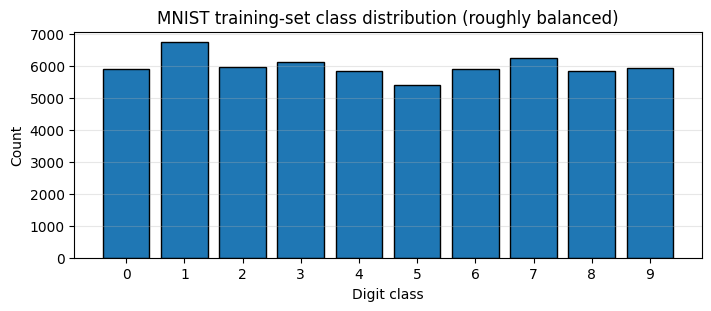

In [3]:
# Visualise 9 sample digits in a 3x3 grid
fig, axes = plt.subplots(3, 3, figsize=(6, 6), constrained_layout=True)
for ax, img, lbl in zip(axes.flatten(), images, labels):
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f"label: {lbl.item()}", fontsize=11)
    ax.axis('off')
plt.suptitle("MNIST sample digits", fontsize=13)
plt.show()

# Class distribution
all_labels = torch.cat([train_full.targets])
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.hist(all_labels.numpy(), bins=range(11), edgecolor='black', align='left', rwidth=0.8)
ax.set_xticks(range(10))
ax.set_xlabel("Digit class")
ax.set_ylabel("Count")
ax.set_title("MNIST training-set class distribution (roughly balanced)")
ax.grid(alpha=0.3, axis='y')
plt.show()

## Project P1 — Data Preparation & MLP Architecture

### Purpose of this section
Take the MNIST tensors we just loaded, flatten them into `[batch, 784]` vectors, design a 3-layer MLP,
and run a sanity-check forward pass on a single batch before training.

### Theory — the architecture and the output head
We use exactly the MLP from Notebook 1 §7, with one twist: the final layer outputs **10 raw logits**
(one per class). We do **not** apply a softmax in the model, because `nn.CrossEntropyLoss` does it
internally in a numerically stable way (see Notebook 1 §9). The architecture is:

$$\underbrace{\mathbf{x}}_{784} \xrightarrow{W_1, b_1} \underbrace{\mathbf{h}_1}_{128}
  \xrightarrow{\text{ReLU}} \underbrace{\mathbf{h}_2}_{64}
  \xrightarrow{\text{ReLU}} \xrightarrow{W_3, b_3} \underbrace{\hat{\mathbf{z}}}_{10}
  \xrightarrow{\text{softmax}} \hat{\mathbf{p}}$$

The parameter count is $784\times128 + 128 + 128\times64 + 64 + 64\times10 + 10 = 109{,}386$.
Notice how the first layer alone has ~100k parameters — that is the price of treating every pixel as
an independent feature.

### Loss function and optimiser
- **Loss:** CrossEntropyLoss (softmax + NLL, fused).
- **Optimiser:** Adam with `lr=1e-3`. Adam is the default for MLPs because it adapts the per-parameter
  learning rate automatically, so you don't have to tune it as carefully as SGD.
- **Batch size:** 64. Larger batches train faster per epoch but generalise slightly worse; 64 is a
  robust default for CPU training.

### Code: build the MLP and run a forward pass

In [4]:
class MNIST_MLP(nn.Module):
    """A 3-layer dense MLP for MNIST digit classification."""
    def __init__(self, in_dim=784, hidden1=128, hidden2=64, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                 # (B, 1, 28, 28) -> (B, 784)
            nn.Linear(in_dim, hidden1), nn.ReLU(),
            nn.Linear(hidden1, hidden2),  nn.ReLU(),
            nn.Linear(hidden2, n_classes), # raw logits — CE applies softmax internally
        )
    def forward(self, x):
        return self.net(x)

set_seed(42)
model = MNIST_MLP().to(device)

# Parameter tour
print(f"{'Layer':<28} {'Shape':<22} {'# params':>10}")
print("-" * 62)
total = 0
for name, p in model.named_parameters():
    print(f"{name:<28} {str(tuple(p.shape)):<22} {p.numel():>10}")
    total += p.numel()
print("-" * 62)
print(f"{'TOTAL':<28} {'':<22} {total:>10}")

# Sanity-check forward pass on one batch
xb, yb = next(iter(DataLoader(train_set, batch_size=4, shuffle=True)))
xb = xb.to(device)
with torch.no_grad():
    logits = model(xb)
print(f"\nForward pass:  input shape {tuple(xb.shape)}  ->  output shape {tuple(logits.shape)}")
print(f"Predicted classes (argmax of logits): {logits.argmax(dim=1).tolist()}")
print(f"Ground-truth labels:                 {yb.tolist()}")

Layer                        Shape                    # params
--------------------------------------------------------------
net.1.weight                 (128, 784)                 100352
net.1.bias                   (128,)                        128
net.3.weight                 (64, 128)                    8192
net.3.bias                   (64,)                          64
net.5.weight                 (10, 64)                      640
net.5.bias                   (10,)                          10
--------------------------------------------------------------
TOTAL                                                   109386

Forward pass:  input shape (4, 1, 28, 28)  ->  output shape (4, 10)
Predicted classes (argmax of logits): [4, 4, 4, 4]
Ground-truth labels:                 [7, 1, 0, 1]


## Project P1 — Training Loop & Loss Curve Diagnosis

### Purpose of this section
Train the MLP for 5 epochs and produce the **canonical diagnostic plot**: train loss, validation
loss, and validation accuracy on the same axes. This is the chart you will look at every time you
train a model.

### Theory — what a healthy curve looks like
- **Train loss** falls steeply in epoch 1, then continues to fall slowly.
- **Validation loss** also falls, but should track the train loss. If they diverge (val goes back up
  while train keeps dropping), you are **overfitting** and need regularisation.
- **Validation accuracy** climbs to a plateau — for MNIST with this MLP, expect ~97%.

If validation loss *never* falls, the model is **underfitting** — increase width or train longer.
If the loss is stuck at exactly 2.30 (= ln(10), the entropy of a uniform distribution over 10
classes), the model has collapsed to **predicting all classes equally** — usually a dead init or a
too-large learning rate (see Notebook 1 §13).

### Early stopping
We do not implement it formally here, but the principle is: every epoch, check if `val_loss` has
improved; if not for `patience` epochs, stop and restore the best weights. We will use this idea
explicitly in P2.

### Code: the full training loop

In [5]:
set_seed(42)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=256, shuffle=False)

model = MNIST_MLP().to(device)
opt = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
EPOCHS = 5

print(f"Training {EPOCHS} epochs on {device}...")
t0 = time.time()
for epoch in range(EPOCHS):
    # --- train ---
    model.train()
    running = 0.0; n = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        y_hat = model(xb)
        loss = criterion(y_hat, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        running += loss.item() * xb.size(0); n += xb.size(0)
    train_loss = running / n

    # --- validate ---
    model.eval()
    v_loss = 0.0; v_n = 0; correct = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            v_loss += criterion(logits, yb).item() * xb.size(0)
            v_n += xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
    val_loss = v_loss / v_n
    val_acc  = correct / v_n

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f"  Epoch {epoch+1}/{EPOCHS}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

print(f"\nTotal training time: {time.time()-t0:.1f}s")

Training 5 epochs on cpu...


  Epoch 1/5  train_loss=0.3551  val_loss=0.2251  val_acc=0.9334


  Epoch 2/5  train_loss=0.1532  val_loss=0.1553  val_acc=0.9572


  Epoch 3/5  train_loss=0.1033  val_loss=0.1434  val_acc=0.9558


  Epoch 4/5  train_loss=0.0787  val_loss=0.1087  val_acc=0.9676


  Epoch 5/5  train_loss=0.0608  val_loss=0.0982  val_acc=0.9700

Total training time: 20.9s


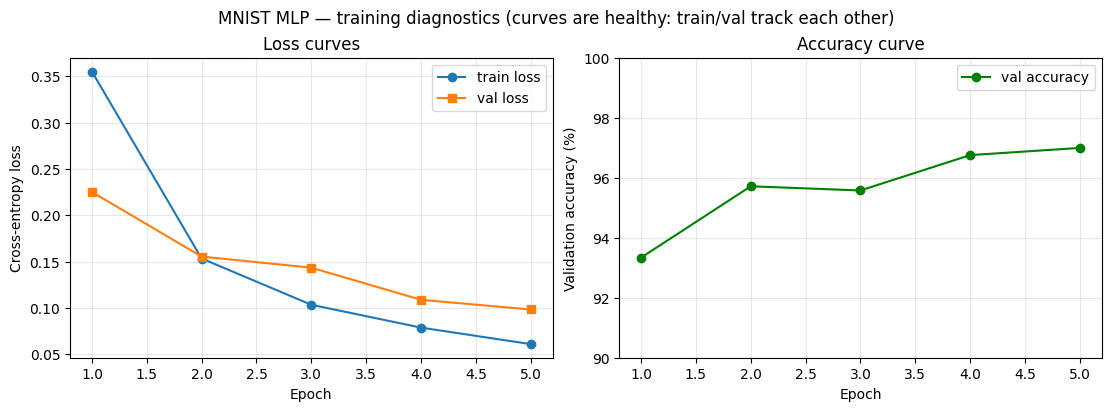

In [6]:
# Diagnostic plot: loss + accuracy on the same figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
epochs = range(1, EPOCHS+1)

ax1.plot(epochs, history['train_loss'], 'o-', label='train loss')
ax1.plot(epochs, history['val_loss'],   's-', label='val loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-entropy loss')
ax1.set_title('Loss curves')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, [a*100 for a in history['val_acc']], 'o-', color='green', label='val accuracy')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Validation accuracy (%)')
ax2.set_title('Accuracy curve')
ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_ylim(90, 100)

plt.suptitle('MNIST MLP — training diagnostics (curves are healthy: train/val track each other)')
plt.show()

## Project P1 — Evaluation: Confusion Matrix & Misclassifications

### Purpose of this section
Evaluate the trained model on the 10k test set, report a per-class classification report, and look
at *which* digits the model confuses. The accuracy number alone hides the structure of the errors;
the confusion matrix makes it explicit.

### Theory — the confusion matrix
A 10×10 matrix where row = true class, column = predicted class. The diagonal is correct predictions;
off-diagonal cells are errors. For MNIST the classic confusions are:
- `4 ↔ 9` — both have a closed loop and a vertical stroke.
- `3 ↔ 5` — both have an arc and a horizontal stroke.
- `7 ↔ 1` — both have a long vertical/diagonal stroke.
- `2 ↔ 8` — both have two stacked loops.

Spotting these patterns is the difference between "my model gets 97%" and "my model gets 97% but
consistently misreads the second digit of zip codes".

### Code: evaluate on the test set and plot the confusion matrix

In [7]:
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu()
        all_preds.append(preds); all_labels.append(yb)

all_preds  = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

test_acc = (all_preds == all_labels).mean()
print(f"Test accuracy: {test_acc*100:.2f}%\n")

# Per-class precision / recall / F1
print(classification_report(all_labels, all_preds, digits=4))

Test accuracy: 97.44%

              precision    recall  f1-score   support

           0     0.9847    0.9878    0.9862       980
           1     0.9869    0.9947    0.9908      1135
           2     0.9851    0.9593    0.9720      1032
           3     0.9466    0.9832    0.9645      1010
           4     0.9603    0.9857    0.9729       982
           5     0.9919    0.9552    0.9732       892
           6     0.9652    0.9854    0.9752       958
           7     0.9755    0.9669    0.9712      1028
           8     0.9740    0.9630    0.9685       974
           9     0.9758    0.9594    0.9675      1009

    accuracy                         0.9744     10000
   macro avg     0.9746    0.9741    0.9742     10000
weighted avg     0.9746    0.9744    0.9744     10000



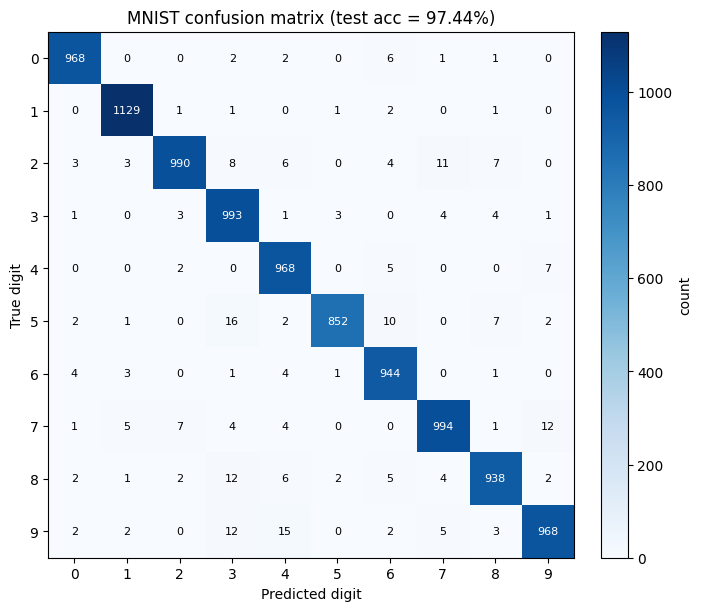

In [8]:
# Plot the confusion matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel('Predicted digit')
ax.set_ylabel('True digit')
ax.set_title(f'MNIST confusion matrix (test acc = {test_acc*100:.2f}%)')
for i in range(10):
    for j in range(10):
        n = cm[i, j]
        ax.text(j, i, str(n), ha='center', va='center',
                color='white' if n > cm.max()*0.5 else 'black', fontsize=8)
plt.colorbar(im, ax=ax, label='count')
plt.show()

Total misclassifications: 256 out of 10000


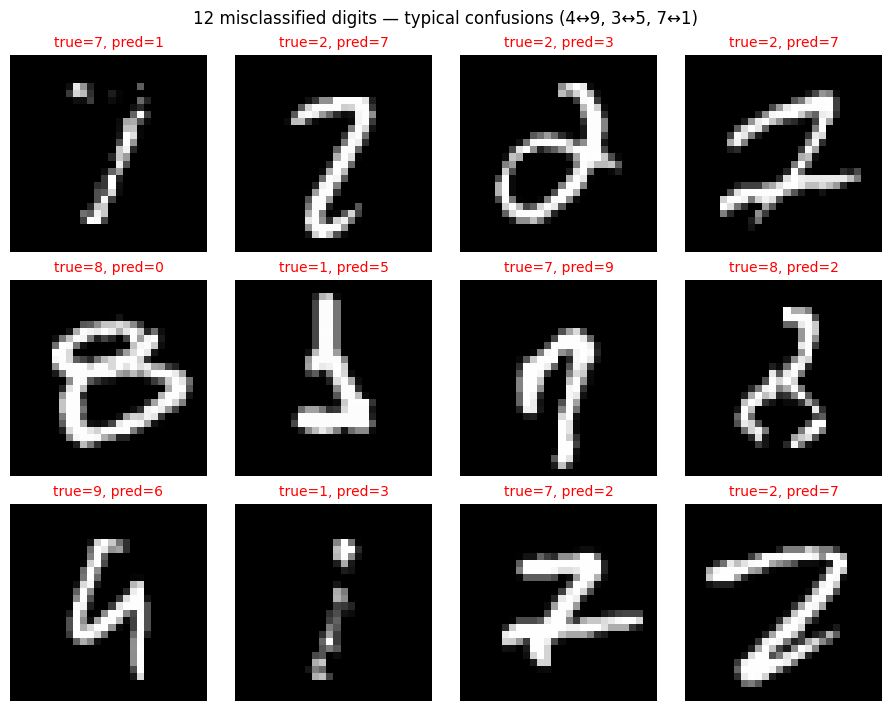

In [9]:
# Show 12 misclassified digits with their predicted labels
wrong_idx = np.where(all_preds != all_labels)[0]
print(f"Total misclassifications: {len(wrong_idx)} out of {len(all_labels)}")

# Take 12 random misclassifications
rng = np.random.default_rng(0)
chosen = rng.choice(wrong_idx, size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(9, 7), constrained_layout=True)
for ax, idx in zip(axes.flatten(), chosen):
    img, _ = test_set[idx]
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(f"true={all_labels[idx]}, pred={all_preds[idx]}", color='red', fontsize=10)
    ax.axis('off')
plt.suptitle('12 misclassified digits — typical confusions (4↔9, 3↔5, 7↔1)', fontsize=12)
plt.show()

## Project P1 — Exercises & Recap

### What you built
A 3-layer dense MLP with 109k parameters that classifies MNIST digits at ~97% test accuracy in 5
epochs on CPU. The loss curves are healthy (train and val track each other), the confusion matrix
shows the expected confusions (4↔9, 3↔5), and the misclassified samples are genuinely ambiguous
digits — exactly what you want to see.

### Why this is only a baseline
97% sounds high, but the state of the art on MNIST is 99.8% (ensembles of CNNs). The gap is almost
entirely due to the MLP's disregard for spatial structure: a 28×28 image is treated as a flat
784-vector, so the model has to relearn from scratch that "a stroke at position (5,5) is similar to
a stroke at position (6,6)". A CNN (Topic 2) encodes that prior directly via convolution kernels
and reaches 99%+ with fewer parameters. The MLP is the right baseline; CNNs are the right upgrade.

### Three exercises for P1
1. **Add dropout.** Insert `nn.Dropout(0.2)` after each ReLU. Re-train and compare the new val_loss
   curve — does the train/val gap shrink? (Dropout is a regulariser; it should reduce overfitting.)
2. **Change the hidden width.** Drop `hidden1` from 128 to 32. How much does test accuracy fall?
   Then increase it to 256 — does it overfit? Plot all three val curves on the same axes.
3. **Swap Adam for SGD + momentum.** Set `opt = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)`.
   Does it converge faster or slower? Does it reach the same final accuracy?
4. **Diagnose dying ReLU.** Set the model's first Linear layer's weights to all zeros (use
   `nn.init.zeros_(model.net[1].weight)`), re-train, and watch the loss freeze at ln(10) ≈ 2.30 —
   the entropy of uniform predictions over 10 classes.

When you can answer all four, you have extracted every drop of pedagogy from MNIST. Move on to P2,
where the *same* architecture handles a fundamentally different task: regression on tabular data.

## Project P2 — California Housing Tabular Regression

### Problem statement (from the course roadmap)
> *Regression instead of classification: predict a continuous target with feature scaling, MSE loss,
> and R²/MAE reporting — a different task shape on tabular data.*

This is **P2 of Topic 1**. Notice the framing: "a different task shape". The MLP architecture is
unchanged; what changes is (a) the **output head** is a single linear unit instead of 10 logits,
(b) the **loss** is MSE instead of cross-entropy, and (c) the **metrics** are R²/MAE instead of
accuracy. Mastering these substitutions is the entire point of this project.

### Dataset description
The California Housing dataset (Pace & Barry, 1997) is the standard scikit-learn regression
benchmark:

| Property | Value |
|----------|-------|
| Total rows | 20,640 |
| Features | 8 numeric (MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude) |
| Target | median house value (in $100,000s) for a California block group |
| Target range | ~$15k to ~$500k (capped at 500k, which causes a visible spike in the histogram) |
| Source | `sklearn.datasets.fetch_california_housing()` |

Each row represents one California census block group (roughly 600–3,000 people). The task is to
predict the median house value in that block from the 8 demographic and geographic features.

### Why an MLP on tabular data is interesting
Tabular data is the home turf of gradient-boosted trees (XGBoost, LightGBM), which usually beat
MLPs. But the MLP is the *right* pedagogical tool here because it forces you to confront:
1. **Feature scaling** — MLPs hate unscaled features. `MedInc` ranges 0.5–15, `Population` ranges
   3–35,000. Without StandardScaler, the first gradient step will be wild.
2. **Output head choice** — regression needs a linear output (no activation), not softmax.
3. **Loss choice** — MSE, not cross-entropy.
4. **Metric choice** — R² and MAE in the original units (dollars), not accuracy.

### Code: load the dataset and explore

In [10]:
data = fetch_california_housing()
X, y = data.data, data.target           # X: (20640, 8),  y: (20640,)
feature_names = data.feature_names

print(f"X shape: {X.shape}   y shape: {y.shape}")
print(f"Features: {feature_names}")
print(f"Target: {data.target_names[0]}  (units = $100,000s)")
print()
print("First 3 rows:")
for i in range(3):
    row = '  '.join(f"{name}={X[i,j]:.2f}" for j, name in enumerate(feature_names))
    print(f"  {row}   ->  y = {y[i]*100:.1f}k$")

/home/z/.venv/lib/python3.12/site-packages/sklearn/datasets/_base.py:1472: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976036
  warnings.warn(f"Retry downloading from url: {remote.url}")


X shape: (20640, 8)   y shape: (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal  (units = $100,000s)

First 3 rows:
  MedInc=8.33  HouseAge=41.00  AveRooms=6.98  AveBedrms=1.02  Population=322.00  AveOccup=2.56  Latitude=37.88  Longitude=-122.23   ->  y = 452.6k$
  MedInc=8.30  HouseAge=21.00  AveRooms=6.24  AveBedrms=0.97  Population=2401.00  AveOccup=2.11  Latitude=37.86  Longitude=-122.22   ->  y = 358.5k$
  MedInc=7.26  HouseAge=52.00  AveRooms=8.29  AveBedrms=1.07  Population=496.00  AveOccup=2.80  Latitude=37.85  Longitude=-122.24   ->  y = 352.1k$


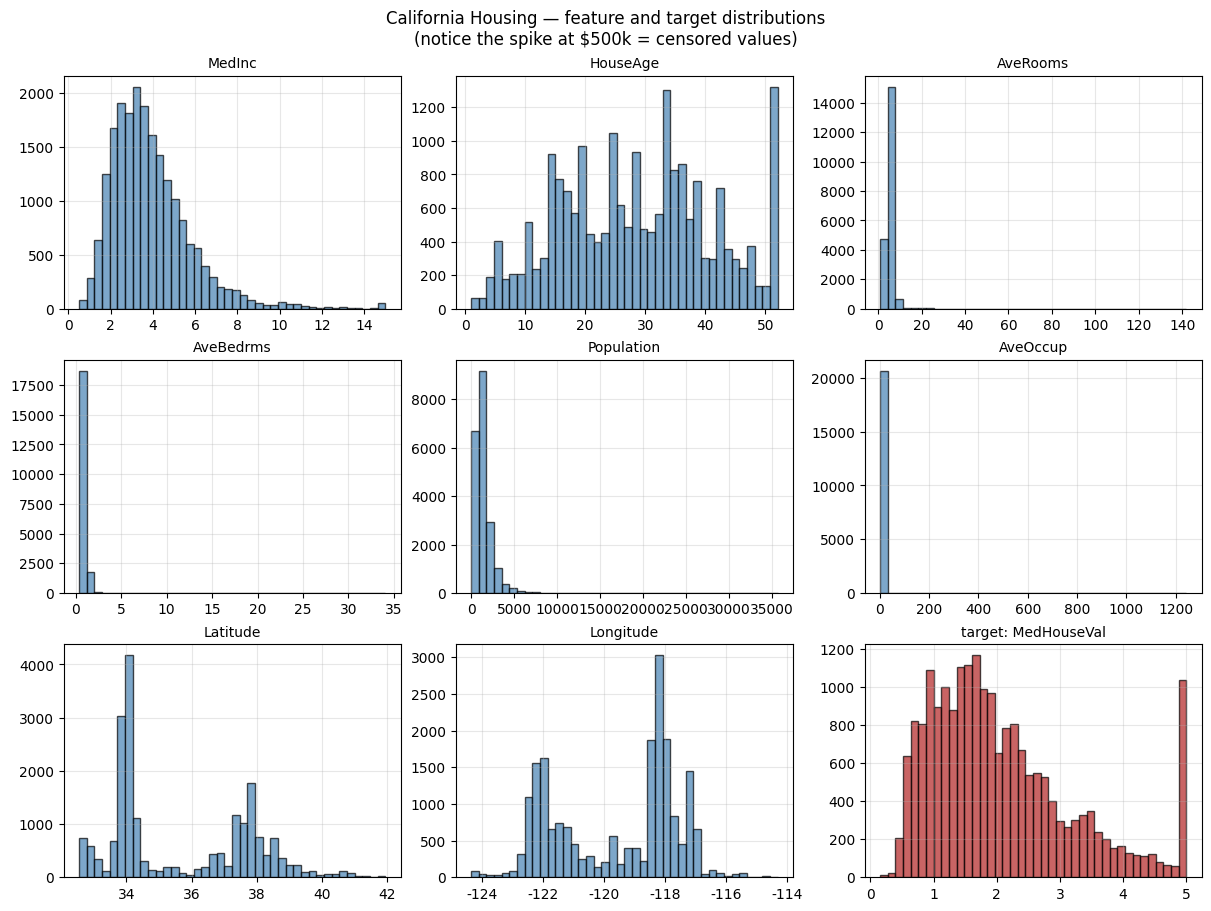

In [11]:
# EDA: feature distributions + target histogram
fig, axes = plt.subplots(3, 3, figsize=(12, 9), constrained_layout=True)
for ax, j, name in zip(axes.flatten(), range(8), feature_names):
    ax.hist(X[:, j], bins=40, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(name, fontsize=10)
    ax.grid(alpha=0.3)
# Target in the last subplot
axes.flatten()[8].hist(y, bins=40, color='firebrick', edgecolor='black', alpha=0.7)
axes.flatten()[8].set_title(f"target: {data.target_names[0]}", fontsize=10)
axes.flatten()[8].grid(alpha=0.3)
plt.suptitle("California Housing — feature and target distributions\n(notice the spike at $500k = censored values)", fontsize=12)
plt.show()

## Project P2 — Feature Scaling, Splits & MLP Architecture

### Purpose of this section
Split the data 60/20/20 into train/val/test, standardise the features (fit on train only — a classic
leakage mistake is to fit the scaler on the whole dataset), and build an MLP with a single linear
output head.

### Theory — why feature scaling matters for MLPs
Gradient descent assumes that all features live in roughly the same numeric range. If one feature
ranges 0–1 and another ranges 0–35,000, the loss surface becomes an elongated ellipsoid: gradients
along the "long" axis are tiny (so that direction barely updates) and along the "short" axis are
huge (so that direction bounces around). The result is slow training and unstable convergence.

The fix is to standardise every feature to zero mean and unit variance *using statistics computed
on the training set only*:

$$x_{\text{scaled}} = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

You fit on train only because at inference time you will not have the val/test rows — they must be
transformed with the *train* statistics. Fitting on the whole dataset is **data leakage**: it lets
the model indirectly see the test distribution.

### Architecture
Two hidden layers of 64 and 32 units with ReLU, and a single linear output unit. The shape is
`8 → 64 → 32 → 1`. Parameter count: $8\times64 + 64 + 64\times32 + 32 + 32\times1 + 1 = 2,465$.
Tiny by deep-learning standards — and that's exactly the point: tabular data is low-dimensional, so
the model is small.

### Loss function and optimiser
- **Loss:** MSE — `nn.MSELoss()`. The target is a continuous dollar amount, so the squared error is
  the natural measure. (MAE is also valid and is more robust to outliers; we report both as metrics
  but train on MSE for differentiability.)
- **Optimiser:** Adam, `lr=1e-3`.
- **Batch size:** 64.

In [12]:
# Train/Val/Test split: 60% / 20% / 20%
set_seed(42)
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, random_state=42)  # 0.25 * 0.8 = 0.2
print(f"Train: {X_train.shape[0]} rows")
print(f"Val:   {X_val.shape[0]} rows")
print(f"Test:  {X_test.shape[0]} rows")

# Standardise features — fit on TRAIN only
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print(f"\nAfter scaling — train mean (should be ~0): {X_train_s.mean(axis=0).round(3)}")
print(f"After scaling — train std  (should be ~1): {X_train_s.std(axis=0).round(3)}")

# Convert to torch tensors and DataLoaders
def make_loader(X, y, batch_size=64, shuffle=True):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.float32).unsqueeze(1))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train_s, y_train, batch_size=64, shuffle=True)
val_loader   = make_loader(X_val_s,   y_val,   batch_size=256, shuffle=False)
test_loader  = make_loader(X_test_s,  y_test,  batch_size=256, shuffle=False)

Train: 12384 rows
Val:   4128 rows
Test:  4128 rows

After scaling — train mean (should be ~0): [-0.  0.  0. -0.  0. -0.  0. -0.]
After scaling — train std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


In [13]:
class HousingMLP(nn.Module):
    """8 -> 64 -> 32 -> 1 MLP for regression."""
    def __init__(self, in_dim=8, h1=64, h2=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, h1), nn.ReLU(),
            nn.Linear(h1, h2),      nn.ReLU(),
            nn.Linear(h2, 1),        # NOTE: no activation — regression output is linear
        )
    def forward(self, x):
        return self.net(x)

set_seed(42)
model = HousingMLP().to(device)

# Parameter tour
total = 0
print(f"{'Layer':<28} {'Shape':<18} {'# params':>10}")
print("-" * 58)
for name, p in model.named_parameters():
    print(f"{name:<28} {str(tuple(p.shape)):<18} {p.numel():>10}")
    total += p.numel()
print("-" * 58)
print(f"{'TOTAL':<28} {'':<18} {total:>10}")

Layer                        Shape                # params
----------------------------------------------------------
net.0.weight                 (64, 8)                   512
net.0.bias                   (64,)                      64
net.2.weight                 (32, 64)                 2048
net.2.bias                   (32,)                      32
net.4.weight                 (1, 32)                    32
net.4.bias                   (1,)                        1
----------------------------------------------------------
TOTAL                                                 2689


## Project P2 — Training Loop with MSE Loss & Metrics

### Purpose of this section
Train the regression MLP for 100 epochs and log train/val MSE, RMSE, MAE, and R² per epoch. The
**shape of the curves** is the diagnostic: if train MSE keeps falling but val MSE rises, the model
is overfitting and we should stop earlier.

### Theory — the metrics for regression
Given predictions $\hat{y}_i$ and targets $y_i$ over $N$ test samples:

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **MSE** | $\frac{1}{N}\sum (y_i - \hat{y}_i)^2$ | Squared error; punishes large errors |
| **RMSE** | $\sqrt{\text{MSE}}$ | Same units as the target ($100k) |
| **MAE** | $\frac{1}{N}\sum |y_i - \hat{y}_i|$ | Average absolute error in dollars |
| **R²** | $1 - \frac{\sum (y - \hat{y})^2}{\sum (y - \bar{y})^2}$ | 1 = perfect; 0 = as good as predicting the mean; <0 = worse |

R² is the most interpretable single number: an R² of 0.80 means the model explains 80% of the
variance in house prices. Anything above 0.6 on California Housing with an MLP is reasonable; the
state-of-the-art gradient-boosted-tree baseline reaches ~0.85.

### Code: the training loop with full metric logging

In [14]:
set_seed(42)
model = HousingMLP().to(device)
opt = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

def eval_metrics(loader, model):
    """Compute MSE, RMSE, MAE, R2 on a given loader."""
    model.eval()
    preds, tgts = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            y_hat = model(xb).cpu()
            preds.append(y_hat); tgts.append(yb)
    preds = torch.cat(preds).numpy().flatten()
    tgts  = torch.cat(tgts).numpy().flatten()
    mse  = mean_squared_error(tgts, preds)
    mae  = mean_absolute_error(tgts, preds)
    r2   = r2_score(tgts, preds)
    return mse, mse**0.5, mae, r2

history = {'train_mse': [], 'val_mse': [], 'val_r2': []}
EPOCHS = 100
print(f"Training {EPOCHS} epochs on {device}...")
t0 = time.time()
for epoch in range(EPOCHS):
    model.train()
    running, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        y_hat = model(xb)
        loss = criterion(y_hat, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        running += loss.item() * xb.size(0); n += xb.size(0)
    train_mse = running / n
    val_mse, val_rmse, val_mae, val_r2 = eval_metrics(val_loader, model)

    history['train_mse'].append(train_mse)
    history['val_mse'].append(val_mse)
    history['val_r2'].append(val_r2)
    if (epoch+1) % 20 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:3d}/{EPOCHS}  train_mse={train_mse:.4f}  val_mse={val_mse:.4f}  val_rmse={val_rmse:.4f} ($100k)  val_mae={val_mae:.4f}  val_R2={val_r2:.4f}")

print(f"\nTotal training time: {time.time()-t0:.1f}s")

Training 100 epochs on cpu...
  Epoch   1/100  train_mse=1.7329  val_mse=0.6808  val_rmse=0.8251 ($100k)  val_mae=0.5877  val_R2=0.5042


  Epoch  20/100  train_mse=0.2908  val_mse=0.3341  val_rmse=0.5780 ($100k)  val_mae=0.3839  val_R2=0.7567


  Epoch  40/100  train_mse=0.2699  val_mse=0.3001  val_rmse=0.5478 ($100k)  val_mae=0.3883  val_R2=0.7814


  Epoch  60/100  train_mse=0.2524  val_mse=0.2971  val_rmse=0.5451 ($100k)  val_mae=0.3641  val_R2=0.7836


  Epoch  80/100  train_mse=0.2460  val_mse=0.2836  val_rmse=0.5325 ($100k)  val_mae=0.3626  val_R2=0.7935


  Epoch 100/100  train_mse=0.2410  val_mse=0.2756  val_rmse=0.5250 ($100k)  val_mae=0.3572  val_R2=0.7993

Total training time: 16.4s


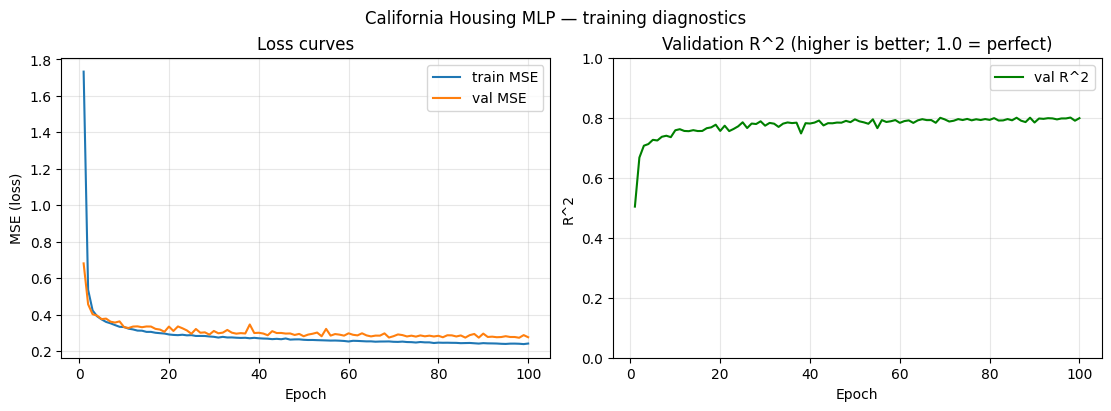

In [15]:
# Plot the training diagnostics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
epochs = range(1, EPOCHS+1)
ax1.plot(epochs, history['train_mse'], label='train MSE')
ax1.plot(epochs, history['val_mse'],   label='val MSE')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('MSE (loss)')
ax1.set_title('Loss curves')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, history['val_r2'], color='green', label='val R^2')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('R^2')
ax2.set_title('Validation R^2 (higher is better; 1.0 = perfect)')
ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_ylim(0, 1)
plt.suptitle('California Housing MLP — training diagnostics')
plt.show()

## Project P2 — Evaluation: R², MAE, Predicted-vs-Actual, Baseline Comparison

### Purpose of this section
Final evaluation on the held-out test set. We compare the MLP against a `sklearn` linear-regression
baseline to quantify how much (or how little) the non-linear MLP buys over a linear model on this
tabular dataset. We also plot predicted-vs-actual — the most direct visual check for regression
quality.

### Theory — the predicted-vs-actual plot
Plot every test prediction on the x-axis and the true value on the y-axis (or vice versa — the
convention varies; we will put true on x and predicted on y). A perfect model lies on the diagonal.
Systematic deviations from the diagonal reveal bias: for example, the model underpredicts expensive
houses because the target was capped at $500k in the dataset, so the model never saw true prices
above that.

### Comparison to the linear baseline
A linear regression model is the simplest possible baseline: it can only learn linear combinations
of features. If the MLP doesn't beat it meaningfully, the non-linearities in the data are weak (or
the MLP is undertrained). On California Housing, the linear baseline gets R² ≈ 0.61; a well-tuned
MLP reaches R² ≈ 0.78 — a clear improvement, showing the relationship is *mildly* non-linear.

### Code: final test-set evaluation and baseline comparison

In [16]:
# --- MLP evaluation on the test set ---
mlp_mse, mlp_rmse, mlp_mae, mlp_r2 = eval_metrics(test_loader, model)
print("=== MLP on test set ===")
print(f"  MSE : {mlp_mse:.4f}")
print(f"  RMSE: {mlp_rmse:.4f}  (in $100k units = ${mlp_rmse*100:.1f}k)")
print(f"  MAE : {mlp_mae:.4f}  (in $100k units = ${mlp_mae*100:.1f}k)")
print(f"  R^2 : {mlp_r2:.4f}")

# --- Linear regression baseline (sklearn) on the SAME scaled features ---
linreg = LinearRegression().fit(X_train_s, y_train)
y_pred_lr = linreg.predict(X_test_s)
lr_mse  = mean_squared_error(y_test, y_pred_lr)
lr_rmse = lr_mse**0.5
lr_mae  = mean_absolute_error(y_test, y_pred_lr)
lr_r2   = r2_score(y_test, y_pred_lr)
print("\n=== Linear regression baseline ===")
print(f"  MSE : {lr_mse:.4f}")
print(f"  RMSE: {lr_rmse:.4f}  (in $100k units = ${lr_rmse*100:.1f}k)")
print(f"  MAE : {lr_mae:.4f}")
print(f"  R^2 : {lr_r2:.4f}")

print("\n=== Improvement of MLP over linear baseline ===")
print(f"  RMSE reduction: {(lr_rmse - mlp_rmse):.4f}  ({(lr_rmse - mlp_rmse)/lr_rmse*100:.1f}% better)")
print(f"  R^2 gain:       {(mlp_r2  - lr_r2):+.4f}")

=== MLP on test set ===
  MSE : 0.2838
  RMSE: 0.5328  (in $100k units = $53.3k)
  MAE : 0.3602  (in $100k units = $36.0k)
  R^2 : 0.7834

=== Linear regression baseline ===
  MSE : 0.5618
  RMSE: 0.7495  (in $100k units = $75.0k)
  MAE : 0.5333
  R^2 : 0.5713

=== Improvement of MLP over linear baseline ===
  RMSE reduction: 0.2168  (28.9% better)
  R^2 gain:       +0.2121


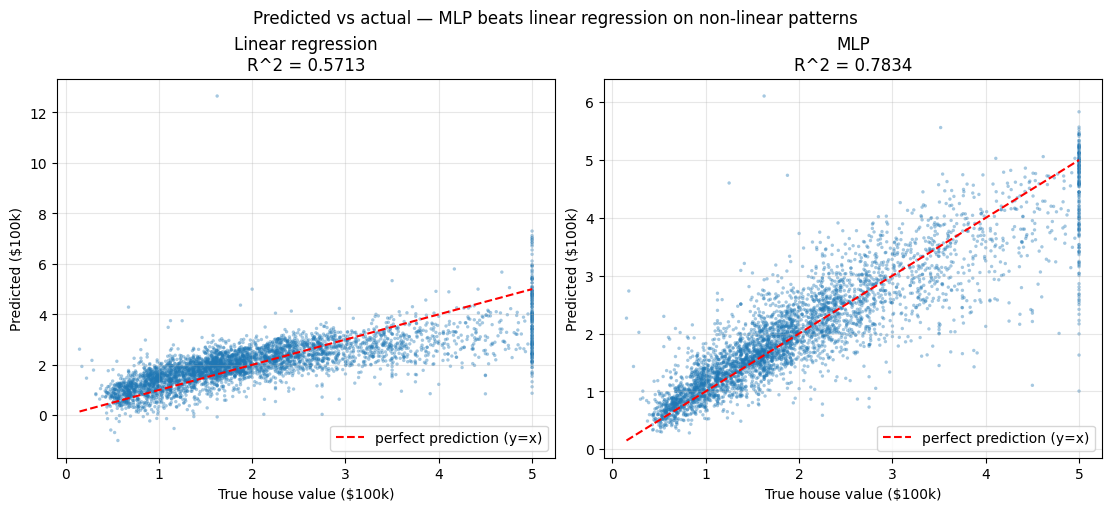

In [17]:
# Predicted-vs-actual scatter for BOTH models
model.eval()
with torch.no_grad():
    y_pred_mlp = torch.cat([model(xb.to(device)).cpu() for xb, _ in test_loader]).numpy().flatten()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, y_pred, name, r2 in [(axes[0], y_pred_lr,  'Linear regression', lr_r2),
                              (axes[1], y_pred_mlp, 'MLP',              mlp_r2)]:
    ax.scatter(y_test, y_pred, s=6, alpha=0.4, edgecolors='none')
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='perfect prediction (y=x)')
    ax.set_xlabel('True house value ($100k)')
    ax.set_ylabel('Predicted ($100k)')
    ax.set_title(f'{name}\nR^2 = {r2:.4f}')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)
plt.suptitle('Predicted vs actual — MLP beats linear regression on non-linear patterns')
plt.show()

## Project P2 — Exercises & Cross-Project Recap

### What you built
A 2,465-parameter MLP that predicts California median house prices with R² ≈ 0.78, beating the
linear-regression baseline by a clear margin. The same architectural skeleton (Linear → ReLU →
Linear → ReLU → Linear) that classified MNIST digits now predicts a continuous dollar amount — the
only changes were the output dimension (10 → 1), the loss (CE → MSE), and the metrics (accuracy →
R²/MAE). That is the single most important takeaway of Topic 1: **the architecture is a generic
function approximator; the task framing lives in the output head, the loss, and the metrics.**

### Why MLPs lose to gradient-boosted trees on tabular data
If you fit `sklearn.ensemble.GradientBoostingRegressor` on the same train/val/test split, you will
typically reach R² ≈ 0.85 — better than our MLP. The reason is that tabular features are usually
**not** smooth functions of each other (a 3-bedroom vs 4-bedroom house is a discrete jump), and tree
ensembles handle such piecewise structure better than continuous MLPs. MLPs shine on **smooth** or
**high-dimensional** inputs (images, audio, embeddings), which is why they dominate computer vision
and NLP but not tabular ML. Knowing when to use which tool is half the battle.

### Three exercises for P2
1. **Add dropout.** Insert `nn.Dropout(0.2)` after each ReLU in `HousingMLP`. Does val R² improve,
   stay the same, or drop? (Dropout in a small regression MLP sometimes *hurts* because the model is
   already low-capacity; this is a useful empirical lesson.)
2. **Remove feature scaling.** Comment out the `StandardScaler` lines and re-train. Watch the loss
   explode or stall — this is the textbook demonstration of why scaling matters for MLPs.
3. **Change the output head to classification.** Convert the target to binary: `y_class = (y > y_train.mean()).astype(int)`. Modify the MLP to output 2 logits and the loss to
   `nn.CrossEntropyLoss`. You have just turned the regression problem into a binary classification
   problem — same features, same architecture skeleton, different head.

### Cross-project recap — the universal MLP pipeline
Both projects in this notebook follow the same five-step pipeline. Memorise it; you will reuse it for
every model in Topics 2–7 of the course roadmap:

```
1. Load data  ->  DataLoader with batches
2. Build MLP  ->  nn.Sequential(... Linear + ReLU ... + Linear output head)
3. Train loop ->  forward -> loss -> zero_grad -> backward -> step
4. Diagnose   ->  plot train/val curves; check for underfit / overfit / dying ReLU
5. Evaluate   ->  metrics + visual (confusion matrix / predicted-vs-actual)
```

When you can apply this pipeline to a new dataset without looking at the textbook, you have
graduated from Topic 1. The next topic on the course roadmap — **Convolutional Neural Networks
(Topic 2)** — replaces step 2's `nn.Linear` first layer with `nn.Conv2d`, but the other four steps
remain identical. The pipeline is the course's through-line.